# TIRT in R

Fit Thurstonian item response theory (TIRT) to 24 teaching triplets. Use the first
90 respondents to estimate the measurement parameters and the remaining 10 to
show how to score new respondents.

For respondent $p$ and statement $j$, TIRT defines expected utility
$m_{pj}=q_j a_j\theta_{p,t(j)}+\nu_j$. Here $a_j$ is the loading,
$q_j$ is the keying sign, $\theta_{p,t(j)}$ is the score on the statement's
trait, and $\nu_j$ is a statement effect.

For the comparison of statements $j$ and $k$, the probability of preferring
$j$ is
$$
\Phi\!\left(\frac{m_{pj}-m_{pk}-\gamma_{jk}}{\sqrt{v_j+v_k}}\right).
$$
The cutpoint $\gamma_{jk}$ shifts the utility difference, and $v_j$ and $v_k$
are statement residual variances. One variance per triplet is fixed at 0.5
to set the residual scale. See [TIRT model and priors](../models/tirt.md).
See the [R Quick start](../guide/getting_started.md#quick-start-in-r) for installation.

## Inspect the design and responses

Each design row assigns a statement to a block position and a trait. Each
response row records a comparison between two statements in that block. A
response of 1 favors the first statement and 0 favors the second. The example
stores comparisons derived from a ranking, so the response format is rank.

In [1]:
library(pyfcirt)

example <- load_example("tirt_study", model = "TIRT")
head(example$design, 3)

  block_id position statement_id trait keying
1       B1        1           S1    T1      1
2       B1        2           S2    T2      1
3       B1        3           S3    T3      1


In [2]:
answers <- example$responses
head(answers, 3)

  person_id block_id statement_1 statement_2 response
1        P1       B1          S1          S2        0
2        P1       B1          S1          S3        1
3        P1       B1          S2          S3        1


## Prepare and inspect the model

Split by respondent so the calibration never sees the held-out answers.
Here `format` describes the table layout and `response_format` describes the
task. `data_coverage()` shows how many respondents and blocks entered the
calibration. `summary()` shows the model specification and prior settings.

In [3]:
new_ids <- tail(unique(answers$person_id), 10L)
is_new <- answers$person_id %in% new_ids

m <- model()
m$add_fc(example$design, answers[!is_new, ], format = example$format,
         model = "TIRT", response_format = example$response_format)
m$prepare()
m$data_coverage()

  model_response_format n_blocks size n_persons n_answered n_missing
1                  TIRT       24    3        90       2160         0


In [4]:
summary(m)

Model: TIRT
90 people, 4 traits, 24 blocks, 72 statements
Observations: 6,480 pair comparisons
Measurements:
  24 blocks, size=3, link=probit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [4 x 4] ~ LKJCorr(n=4, eta=1)
Priors:
    loading [72] ~ LogNormal(mu=0, sigma=0.5)
    statement_effect [72] ~ Normal(mu=0, sigma=sqrt(residual_variance))
    residual_variance [48] ~ HalfNormal(loc=0, scale=1)
    cutpoint [72] ~ Normal(mu=0, sigma=1)
Constraints:
    residual_variance: fixed=0.5 [24 fixed]


## Fit and summarize one block

After fitting, use `coef()` to inspect one block. Statement rows show loadings
and residual variances. Comparison rows show cutpoints for the labelled pairs.
A fixed parameter has a mean and blank uncertainty columns.

In [5]:
m$fit(draws = 500L, tune = 700L, chains = 4L,
      nuts_sampler = "numpyro", random_seed = 42L)

In [6]:
coef(m, blocks = "B1", kind = "stats", digits = 2L)

 unit statement trait    pair position         parameter  mean   sd hdi95_lb  hdi95_ub
   B1        S1    T1     NaN      NaN           loading  0.74 0.19     0.44      1.15
   B1        S2    T2     NaN      NaN           loading  0.99 0.23     0.57      1.44
   B1        S3    T3     NaN      NaN           loading  1.01 0.23     0.61      1.49
   B1        S1    T1     NaN      NaN residual_variance  0.50
   B1        S2    T2     NaN      NaN residual_variance  1.25 0.61     0.23      2.57
   B1        S3    T3     NaN      NaN residual_variance  0.95 0.58     0.01      1.99
   B1       NaN   NaN S1 > S2        1          cutpoint -0.24 0.70    -1.68      0.98
   B1       NaN   NaN S1 > S3        1          cutpoint  0.04 0.67    -1.36      1.30
   B1       NaN   NaN S2 > S3        1          cutpoint -0.39 0.71    -1.71      1.05


## Check replicated responses

For block B1, compare the observed and replicated Pearson discrepancies.
The histogram shows the replicated discrepancy minus the observed discrepancy.
Zero marks equal discrepancy in the observed and replicated data. In this run,
45% of the 200 replications had a larger discrepancy than the observed data.
The Monte Carlo standard error is unavailable for a subset of posterior draws.

In [7]:
check <- m$chi_ppp(blocks = "B1", draws = 200L, random_seed = 43L)
check$summary

$PPP
[1] 0.45

$PPP_mcse
[1] NaN

$n_obs
[1] 270



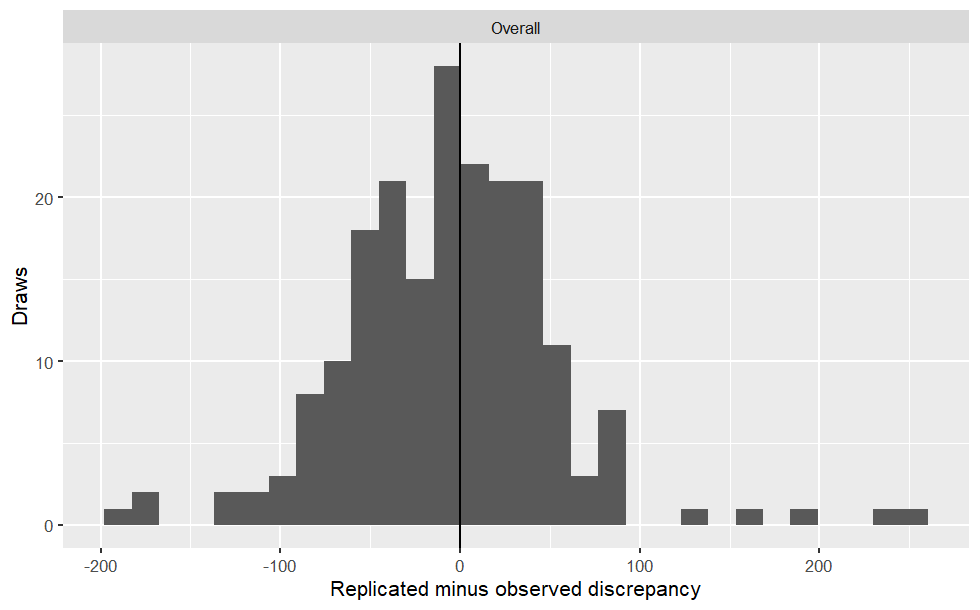

In [8]:
plot_ppp(check)

## Score new respondents

Reuse the fitted measurement parameters and estimate trait scores for the
10 held-out respondents. Select one person by ID before transferring the
posterior draws to R. The plot shows the posterior median and central 95%
credible interval for each trait.

In [9]:
scored <- m$score(answers[is_new, ], format = example$format,
                  draws = 500L, tune = 700L, chains = 4L,
                  nuts_sampler = "numpyro", random_seed = 44L)
scored$data_coverage()

  model_response_format n_blocks size n_persons n_answered n_missing
1                  TIRT       24    3        10        240         0


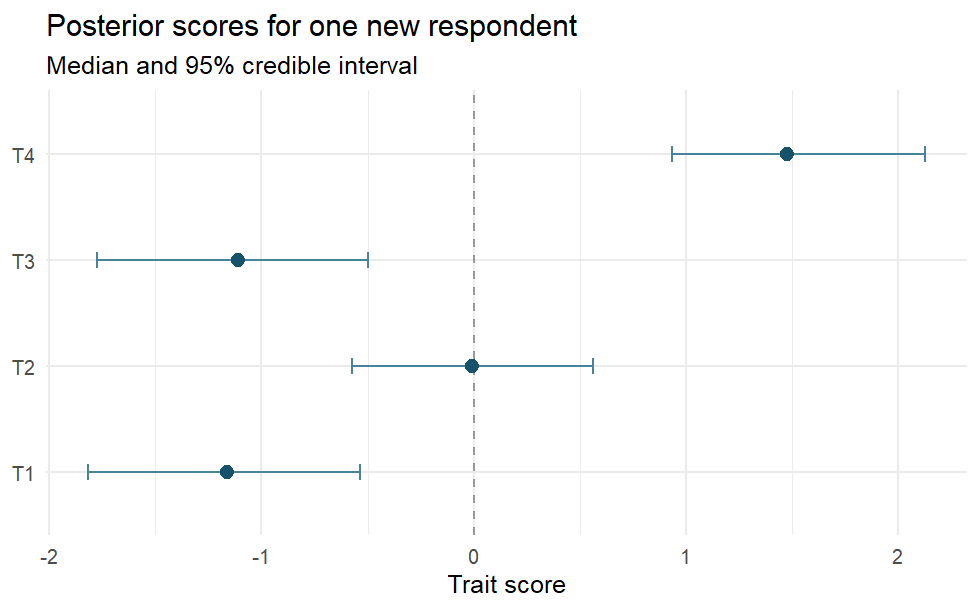

In [10]:
draws <- as_draws(scored, variables = "theta", coords = list(person = new_ids[1L]))
scores <- posterior::summarise_draws(
  draws, "median", ~ posterior::quantile2(.x, probs = c(0.025, 0.975))
)
scores$trait <- attr(draws, "coordinates")$theta$trait

ggplot2::ggplot(scores, ggplot2::aes(x = median, y = trait)) +
  ggplot2::geom_vline(xintercept = 0, linetype = 2, color = "grey60") +
  ggplot2::geom_errorbar(ggplot2::aes(xmin = q2.5, xmax = q97.5),
                         orientation = "y", width = 0.15, color = "#47849a") +
  ggplot2::geom_point(color = "#16536b", size = 3) +
  ggplot2::labs(x = "Trait score", y = NULL, title = "Posterior scores for one new respondent",
                subtitle = "Median and 95% credible interval") +
  ggplot2::theme_minimal(base_size = 13)

## Save and restore the fit

Save the posterior to NetCDF. To restore it, prepare the same calibration design
and responses, then attach the saved samples. The posterior draws and their
labels are the same in both models.

In [11]:
path <- tempfile(fileext = ".nc")
save_results(m, path)

restored <- model()
restored$add_fc(example$design, answers[!is_new, ], format = example$format,
                model = "TIRT", response_format = example$response_format)
restored$prepare()
restored$attach_samples(path)

identical(as_draws(m, variables = "loading"),
          as_draws(restored, variables = "loading"))

[1] TRUE


See the [R API reference](../reference/r_api.md) for signatures, options and return values.